

# TALLER 4 - One-class SVM

<br>

**Autores**

Carlos Caicedo  
Salomón Avila

 

## Planteamiento

One-Class SVM extiende la idea de margen suave vista en clase al caso en que todos los datos de entrenamiento pertenecen a una sola clase. El modelo busca una frontera que englobe la mayoría de los datos y deja por fuera una pequeña proporción de ellos, que se consideran anómalos. Igual que en la formulación dual, la frontera depende solo de productos internos, por lo que se puede usar el truco del kernel con un kernel RBF $K(x,z)=\exp(-\gamma\|x-z\|^2)$, que permite fronteras no lineales en un espacio de dimensión infinita.

El hiperparámetro $\nu$ controla aproximadamente qué proporción de los datos se permite considerar como anomalía durante el entrenamiento. El hiperparámetro $\gamma$ controla la complejidad de la frontera, donde un valor pequeño produce una frontera suave y un valor grande produce una frontera ajustada a cada dato con riesgo de sobreajuste.

Como el método es costoso, se entrena un modelo por cada dígito del conjunto de test de MNIST, con cerca de mil imágenes cada uno. Las imágenes con menor valor de la función de decisión son las más alejadas de la frontera hacia afuera y por tanto las más anómalas.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.svm import OneClassSVM

df = pd.read_csv("mnist_test.csv")
y = df["label"].values
X = df.drop(columns="label").values / 255.0
print(X.shape, np.bincount(y))

(10000, 784) [ 980 1135 1032 1010  982  892  958 1028  974 1009]


## Exploración de hiperparámetros

Se toma el dígito 0 y se varían $\nu$ y $\gamma$. Para cada combinación se reporta la fracción de imágenes marcadas como anómalas y la fracción de vectores de soporte. La opción `scale` es un valor de $\gamma$ que scikit-learn calcula automáticamente a partir de los datos.

In [2]:
X0 = X[y == 0]
filas = []
for nu in [0.01, 0.05, 0.1]:
    for gamma in [0.001, "scale", 0.1, 1.0]:
        m = OneClassSVM(kernel="rbf", nu=nu, gamma=gamma).fit(X0)
        filas.append({"nu": nu, "gamma": gamma,
                      "frac_anomalas": np.mean(m.predict(X0) == -1),
                      "frac_vectores_soporte": len(m.support_) / len(X0)})
pd.DataFrame(filas).round(3)

,nu,gamma,frac_anomalas,frac_vectores_soporte
0,0.01,0.001,0.012,0.027
1,0.01,scale,0.030,0.055
2,0.01,0.1,0.527,0.934
3,0.01,1.0,0.682,1.000
4,0.05,0.001,0.052,0.061
5,0.05,scale,0.054,0.080
6,0.05,0.1,0.505,0.947
7,0.05,1.0,0.800,1.000
8,0.10,0.001,0.101,0.110
9,0.10,scale,0.099,0.122


Con $\gamma$ pequeño o igual a `scale` la fracción de anomalías se mantiene cerca de $\nu$, lo que confirma que $\nu$ fija aproximadamente la proporción de datos fuera de la frontera. Cuando $\gamma$ crece, la frontera se ajusta a cada imagen de forma individual, casi todos los puntos se vuelven vectores de soporte, la fracción de anomalías queda muy por encima de $\nu$ y el modelo deja de describir la distribución, que es el sobreajuste esperado para un $\gamma$ grande. Por esto se eligen $\nu=0.05$ y $\gamma=$ `scale`.

Dígito 0: 0.054 anómalas de 980
Dígito 1: 0.051 anómalas de 1135
Dígito 2: 0.059 anómalas de 1032
Dígito 3: 0.055 anómalas de 1010
Dígito 4: 0.053 anómalas de 982
Dígito 5: 0.058 anómalas de 892
Dígito 6: 0.056 anómalas de 958
Dígito 7: 0.052 anómalas de 1028
Dígito 8: 0.053 anómalas de 974
Dígito 9: 0.056 anómalas de 1009


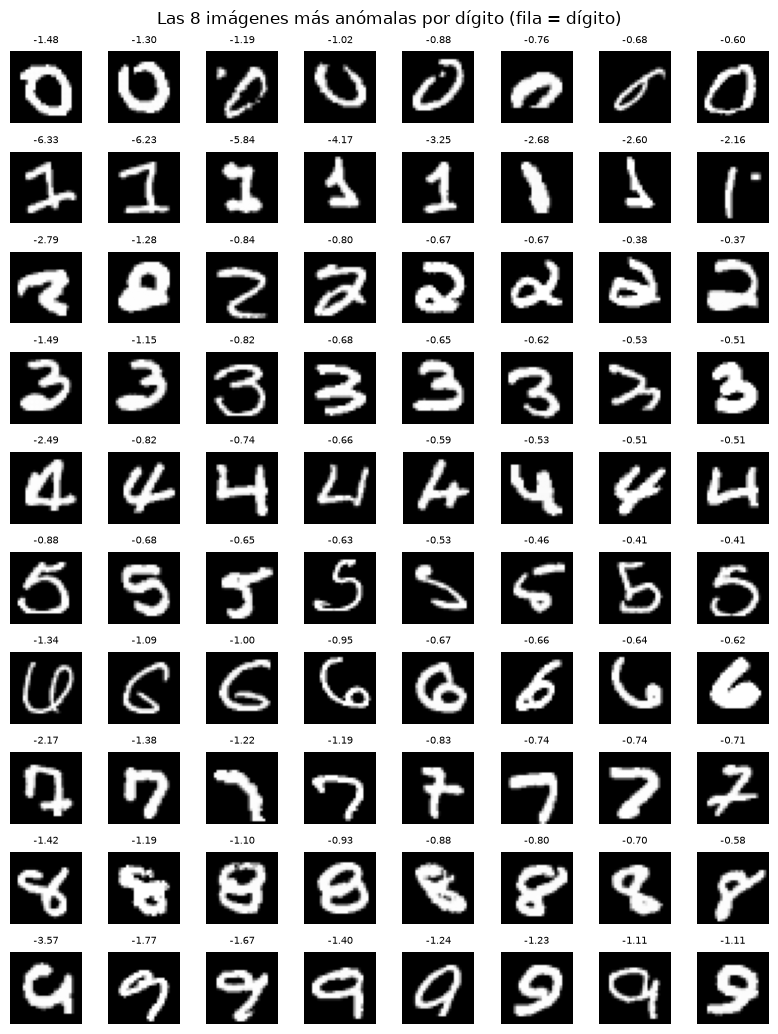

In [3]:
k = 8
fig, ax = plt.subplots(10, k, figsize=(k, 10.5))
for d in range(10):
    Xd = X[y == d]
    m = OneClassSVM(kernel="rbf", nu=0.05, gamma="scale").fit(Xd)
    s = m.decision_function(Xd)
    print(f"Dígito {d}: {np.mean(s < 0):.3f} anómalas de {len(Xd)}")
    for j, i in enumerate(np.argsort(s)[:k]):
        ax[d, j].imshow(Xd[i].reshape(28, 28), cmap="gray")
        ax[d, j].set_title(f"{s[i]:.2f}", fontsize=7)
        ax[d, j].axis("off")
plt.suptitle("Las 8 imágenes más anómalas por dígito (fila = dígito)")
plt.tight_layout(); plt.show()

## Resultados

Con $\nu=0.05$ y kernel RBF cada modelo marca entre el 5 % y el 6 % de las imágenes de su dígito como anómalas, en línea con el valor de $\nu$. Las imágenes con la función de decisión más negativa no son ruido sino dígitos escritos de forma atípica respecto a la distribución de su clase.

Las anomalías encontradas corresponden a trazos muy gruesos o muy delgados, dígitos inclinados o desplazados del centro y formas poco comunes. En el dígito 1 se detectan los unos escritos con base y serifa, que se alejan del trazo vertical simple que domina la clase y por eso obtienen los valores más negativos de todo el conjunto. En el 7 aparecen sietes con barra horizontal o con el trazo cortado, en el 2 aparecen doses con lazo y uno que parece una Z, en el 4 aparecen cuatros cerrados y en el 9 aparecen nueves que se confunden con un 4 o con una a. En los dígitos 0, 6 y 8 sobresalen trazos incompletos o muy deformados, como ceros abiertos y ochos borrosos.

Lo más interesante es que el modelo nunca vio una etiqueta que le dijera qué es un dígito raro y aun así terminó señalando justo las imágenes que haría dudar a cualquier persona. Basta con que la frontera envuelva lo que la mayoría de la clase tiene en común para que lo que queda por fuera hable por sí solo, y por eso varios de los dígitos marcados se confunden con otra clase o con una letra. Mientras $\nu$ fija cuántas imágenes quedan por fuera, $\gamma$ decide si la frontera captura la forma general de un dígito o si se pierde memorizando cada trazo hasta ver anomalías en casi todo el conjunto.

## Referencias

- scikit-learn. *One-Class SVM*. https://scikit-learn.org/stable/modules/generated/sklearn.svm.OneClassSVM.html
- oddrationale. *MNIST in CSV*. Kaggle. https://www.kaggle.com/datasets/oddrationale/mnist-in-csv